# 01 - Logistic Regression

**What is it?** Logistic Regression is a linear classifier. It gives each feature a weight (coefficient), adds them up, and passes the sum through a sigmoid function to get a **probability of churn** between 0 and 1. If the probability is >= 0.5 the customer is predicted as *Attrited*.

**Why use it here?**
- It is the standard **baseline** for binary classification - fast, stable, and hard to overfit.
- Its coefficients are **interpretable**: we can see which features push a customer towards leaving.
- It outputs probabilities, which we need for the AUC score.

**What it needs from the data:** numeric, similarly scaled features with limited skew - handled by the preprocessing pipeline (one-hot encoding + Yeo-Johnson power transform, see `00_prepare_data`).

Run `00_prepare_data.ipynb` first. Every model uses the same 80/20 stratified split (seed 42).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

from common import (CLASS_NAMES, SEED, compute_metrics, get_train_test,
                    plot_confusion_matrix, plot_roc_curve, train_and_evaluate)

## 1. Model
- `max_iter=1000` - gives the solver enough iterations to converge.
- Default regularization (L2, `C=1.0`) - keeps coefficients small so the model doesn't overfit.
- `random_state=SEED` - reproducible results.

In [2]:
model = LogisticRegression(max_iter=1000, random_state=SEED)
model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## 2. Train & evaluate
`train_and_evaluate()` builds the pipeline (preprocessing + model), fits it **on the training set only**, scores the test set, and saves `model/logistic_regression.joblib` and `results/metrics.csv`.

In [3]:
result = train_and_evaluate("logistic_regression", model)
pd.DataFrame([result["metrics"]], index=["Logistic Regression"])

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9161,0.9316,0.8189,0.6123,0.7007,0.6624


**How to read the metrics (positive class = Attrited):**

| Metric | Meaning for this problem |
|---|---|
| Accuracy | % of all customers classified correctly - misleading alone, since 84% are Existing |
| AUC | How well the model *ranks* churners above non-churners (0.5 = random, 1 = perfect) |
| Precision | Of the customers we flag as leaving, how many really leave |
| Recall | Of the customers who really leave, how many we catch |
| F1 | Balance of Precision and Recall |
| MCC | Correlation between predictions and truth (-1 to 1); reliable even with imbalanced classes |

## 3. Overfitting check (train vs test)

In [4]:
X_train, X_test, y_train, y_test = get_train_test()
pipe = result["pipeline"]
train_metrics = compute_metrics(y_train, pipe.predict(X_train), pipe.predict_proba(X_train)[:, 1])
pd.DataFrame([train_metrics, result["metrics"]], index=["Train", "Test"]).round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Train,0.9164,0.9404,0.7940,0.6482,0.7137,0.6701
Test,0.9161,0.9316,0.8189,0.6123,0.7007,0.6624


**Observation:** train and test scores are almost the same (e.g. F1 0.71 vs 0.70) -> **no overfitting**. If anything the model is slightly too simple (underfitting), which is expected for a linear model.

## 4. Confusion matrix

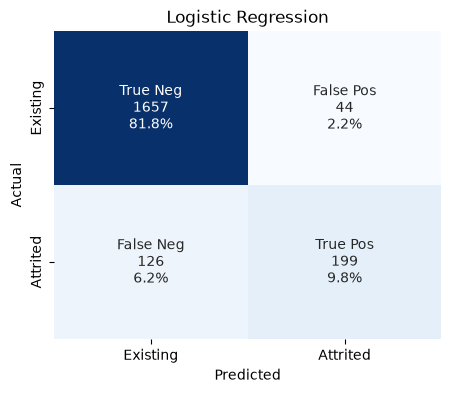

In [5]:
plot_confusion_matrix(result["y_test"], result["y_pred"], title="Logistic Regression")

**Observation:**
- **True Pos 199** - churners correctly caught; **False Neg 126** - churners the model **missed** (39% of all churners).
- **False Pos 44** - loyal customers wrongly flagged. Very few, which is why Precision (0.82) is high.
- The model is **cautious**: when it says "will leave" it is usually right, but it misses many leavers.

## 5. Classification report

In [6]:
print(classification_report(result["y_test"], result["y_pred"], target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

    Existing     0.9293    0.9741    0.9512      1701
    Attrited     0.8189    0.6123    0.7007       325

    accuracy                         0.9161      2026
   macro avg     0.8741    0.7932    0.8260      2026
weighted avg     0.9116    0.9161    0.9110      2026



## 6. ROC curve

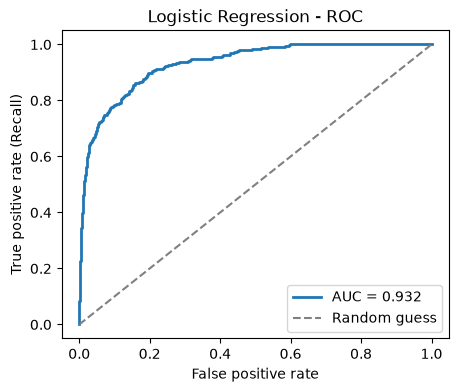

In [7]:
plot_roc_curve(result["y_test"], result["y_prob"], title="Logistic Regression - ROC")

**Observation:** AUC = 0.93 - the model ranks churners above non-churners 93% of the time. The ranking is good; the weak Recall comes from the default 0.5 threshold, not from poor separation.

## 7. What drives the prediction? (coefficients)
Positive coefficient -> pushes towards **Attrited**; negative -> towards **Existing**. Features are on the same (transformed) scale, so the sizes can be compared.

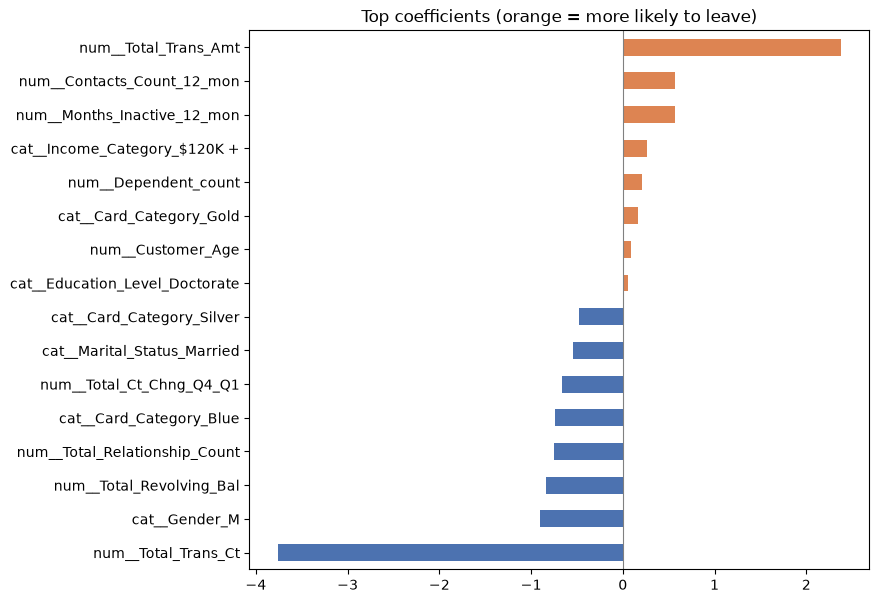

In [8]:
names = pipe.named_steps["prep"].get_feature_names_out()
coef = pd.Series(pipe.named_steps["clf"].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
ax = top.plot.barh(color=["#4C72B0" if v < 0 else "#DD8452" for v in top], figsize=(8, 7))
ax.axvline(0, c="grey", lw=0.8)
ax.set_title("Top coefficients (orange = more likely to leave)")
plt.show()

**Observation:**
- **Total_Trans_Ct** has by far the strongest effect (-3.8): fewer transactions -> much more likely to leave. Matches the EDA.
- Total_Revolving_Bal, Total_Relationship_Count and Total_Ct_Chng_Q4_Q1 are also negative: customers with a balance, more products and stable activity stay.
- Months_Inactive and Contacts_Count are positive: inactivity and frequent calls to the bank signal churn.
- **Total_Trans_Amt is positive (+2.4)** even though churners spend less overall. This is a side effect of its 0.81 correlation with Total_Trans_Ct: *for the same number of transactions*, larger amounts lean towards churn. Coefficients of correlated features should be read together, not one by one.

## 8. Experiment: class weights for the imbalance
In `00_prepare_data` (Step 6) we decided: train a baseline first, and try `class_weight="balanced"` only if churner Recall is poor. Recall = 0.61 means 4 in 10 churners are missed, so we test it.

In [9]:
# same pipeline with class weights; evaluated only, not saved
from sklearn.pipeline import Pipeline
from common import build_preprocessor

balanced = Pipeline([("prep", build_preprocessor(X_train)),
                     ("clf", LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced"))])
balanced.fit(X_train, y_train)
balanced_metrics = compute_metrics(y_test, balanced.predict(X_test), balanced.predict_proba(X_test)[:, 1])
pd.DataFrame([result["metrics"], balanced_metrics], index=["Default (saved)", "class_weight=balanced"]).round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Default (saved),0.9161,0.9316,0.8189,0.6123,0.7007,0.6624
class_weight=balanced,0.8623,0.9334,0.5469,0.8246,0.6577,0.5949


**Observation:** balanced weights raise **Recall from 0.61 to 0.82** (catches 69 more churners: 268 vs 199), but Precision falls from 0.82 to 0.55, and **F1 (0.70 -> 0.66) and MCC (0.66 -> 0.59) both drop**. AUC is unchanged - the model ranks customers the same way; class weights only move the decision threshold.

**Action needed? No - keep the default model as the saved one.** Why:
- It wins on the two balanced metrics (F1, MCC) we chose for this imbalanced problem.
- KNN and Naive Bayes don't support `class_weight`, so keeping all five models at their defaults gives a **fair comparison**.
- If the business cares more about catching every churner than about false alarms (retention offers are cheap), the balanced version is the better choice - this is a business decision, not a modelling one.

## Summary - Logistic Regression
- **Accuracy 0.916, AUC 0.932, Precision 0.819, Recall 0.612, F1 0.701, MCC 0.662.**
- No overfitting; good ranking ability (AUC 0.93), but misses ~39% of churners at the default threshold.
- Linear model -> it cannot capture interactions (e.g. low count *and* low amount together), which tree-based models may handle better.